# 02 - Huấn luyện và so sánh 2 mô hình
Dùng thư viện `src/`. Cần đã chạy `experiments/train_models.py` (nạp mô hình từ checkpoints), hoặc huấn luyện ngay trong notebook ở ô dưới.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # de import duoc package `src`
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.config import load_config
from src.preprocessing.data_loader import load_raw, load_splits, to_xy
cfg = load_config()
from src.models.model_builder import build_pipeline, score
from src.models.model_inspector import top_features
from src.evaluation.metrics import at_threshold, majority_baseline, threshold_free
from src.evaluation.thresholds import build_policy
df = load_raw(cfg); sp = load_splits(df, cfg)
Xtr, ytr, _ = to_xy(df.iloc[sp["train"]], cfg)
Xva, yva, _ = to_xy(df.iloc[sp["val"]], cfg)
Xte, yte, att = to_xy(df.iloc[sp["test"]], cfg)

In [2]:
models = {}
for name in ("random_forest", "logreg"):
    pipe = build_pipeline(name, cfg).fit(Xtr, ytr)
    s_val = score(pipe, Xva)
    pol, extra = build_policy(yva, s_val, cfg)      # ngưỡng chọn trên VALIDATION
    models[name] = (pipe, extra["t_f1_max"], pol)
    print(name, "ngưỡng operating =", round(extra["t_f1_max"], 4))

random_forest ngưỡng operating = 0.4113
logreg ngưỡng operating = 0.9864


## Kết quả trên tập test (precision / recall / F1 / false positive)

In [3]:
rows = []
for name, (pipe, thr, pol) in models.items():
    s = score(pipe, Xte)
    for label, t in (("mặc định 0.5", 0.5), ("operating (F1-max trên val)", thr), ("t_alert", pol.t_alert), ("t_review", pol.t_review)):
        m = at_threshold(yte, s, t)
        rows.append({"mô hình": name, "điểm vận hành": label, "ngưỡng": round(t, 4), "precision": m["precision"],
                     "recall": m["recall"], "f1": m["f1"], "FP": m["fp"], "FN": m["fn"]})
pd.DataFrame(rows).round(4)

,mô hình,điểm vận hành,ngưỡng,precision,recall,f1,FP,FN
0,random_forest,mặc định 0.5,0.5000,1.0000,0.9951,0.9975,0,9
1,random_forest,operating (F1-max trên val),0.4113,0.9995,0.9978,0.9986,1,4
2,random_forest,t_alert,0.4113,0.9995,0.9978,0.9986,1,4
3,random_forest,t_review,0.1539,0.9341,0.9995,0.9657,129,1
4,logreg,mặc định 0.5,0.5000,0.6488,0.9770,0.7798,968,42
5,logreg,operating (F1-max trên val),0.9864,0.9595,0.9590,0.9593,74,75
6,logreg,t_alert,0.9999,0.0000,0.0000,0.0000,0,1830
7,logreg,t_review,0.0093,0.2149,1.0000,0.3538,6686,0


In [4]:
b = majority_baseline(yte)
print(f"Baseline 'luôn Benign': accuracy={b['accuracy']:.4f}, recall={b['recall']:.1f}")

Baseline 'luôn Benign': accuracy=0.9765, recall=0.0


## Đặc trưng quan trọng

In [5]:
for name, (pipe, _, _) in models.items():
    print(name); display(pd.DataFrame(top_features(pipe, list(Xte.columns), 8)))

random_forest


,feature,importance
0,Bwd Header Length,0.105785
1,Fwd Packet Length Std,0.082911
2,Init Bwd Win Bytes,0.051522
3,Packet Length Std,0.043756
4,Subflow Bwd Packets,0.038398
5,Init Fwd Win Bytes,0.037120
6,Packet Length Variance,0.033150
7,Fwd Seg Size Min,0.031955


logreg


,feature,importance
0,Packet Length Mean,12.205394
1,Fwd Packet Length Max,9.963208
2,Bwd Packet Length Mean,9.202539
3,Avg Bwd Segment Size,9.202539
4,Bwd Header Length,8.213927
5,Bwd Packet Length Std,7.976040
6,Bwd Packet Length Min,7.477710
7,Total Fwd Packets,7.132124


## Precision-Recall

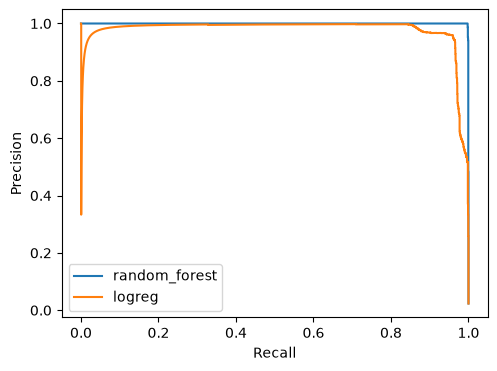

In [6]:
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(5.5, 4))
for name, (pipe, _, _) in models.items():
    p, r, _ = precision_recall_curve(yte, score(pipe, Xte)); ax.plot(r, p, label=name)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(); plt.show()